<a href="https://colab.research.google.com/github/srujanagalla007-beep/AI-Trip-Planner/blob/main/miniproject(final).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

df=pd.read_csv('/content/StudentPerformanceFactors.csv')

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [ ]:

print("First five rows:")
display(df.head())

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())


First five rows:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


Dataset shape: (6607, 20)

Column names:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [ ]:

df = df.drop_duplicates()

for col in df.columns:
    if df[col].isnull().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after cleaning:")
print(df.isnull().sum().sum())

print("Dataset shape after cleaning:", df.shape)


Missing values after cleaning:
0
Dataset shape after cleaning: (6607, 20)


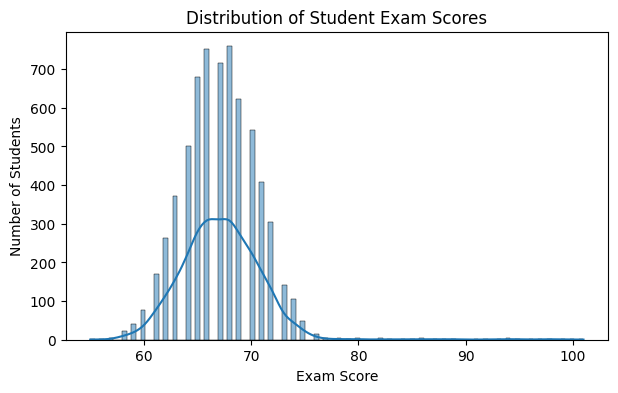

In [ ]:

plt.figure(figsize=(7, 4))
sns.histplot(df["Exam_Score"], kde=True)
plt.title("Distribution of Student Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.show()


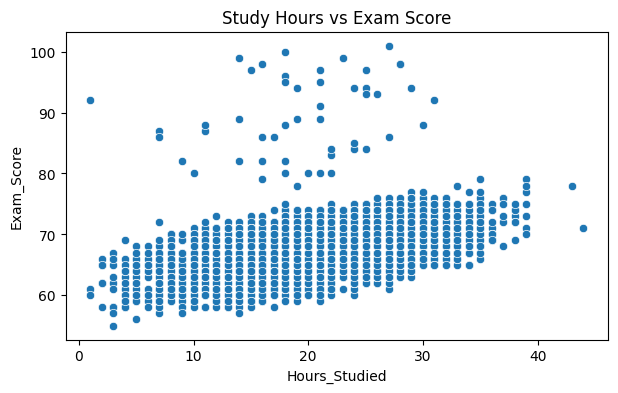

In [ ]:

if "Hours_Studied" in df.columns:
    plt.figure(figsize=(7, 4))
    sns.scatterplot(data=df, x="Hours_Studied", y="Exam_Score")
    plt.title("Study Hours vs Exam Score")
    plt.show()


In [ ]:

X = df.drop(columns=["Exam_Score"])
y = df["Exam_Score"]

# Convert categorical columns into numerical columns
X = pd.get_dummies(X, drop_first=True)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (5285, 27)
Testing data: (1322, 27)


In [ ]:

from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("Root Mean Squared Error:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))


Mean Absolute Error: 0.45239200896259657
Mean Squared Error: 3.2560199870428943
Root Mean Squared Error: 1.804444509272284
R2 Score: 0.7696495724907312


In [ ]:

from sklearn.tree import DecisionTreeRegressor

tree_reg = DecisionTreeRegressor(max_depth=5, random_state=42)
tree_reg.fit(X_train, y_train)

tree_pred = tree_reg.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, tree_pred))
print("Mean Squared Error:", mean_squared_error(y_test, tree_pred))
print("Root Mean Squared Error:", np.sqrt(mean_squared_error(y_test, tree_pred)))
print("R2 Score:", r2_score(y_test, tree_pred))


Mean Absolute Error: 1.599790342214637
Mean Squared Error: 6.3079793483322755
Root Mean Squared Error: 2.511569100847571
R2 Score: 0.5537356203615846


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Create two performance categories
threshold = df["Exam_Score"].median()
y_class = (df["Exam_Score"] >= threshold).astype(int)

# Split the data
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_class, test_size=0.2, random_state=42, stratify=y_class
)

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_c)
X_test_scaled = scaler.transform(X_test_c)

# Train Logistic Regression
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled, y_train_c)

# Make predictions
y_pred_c = log_model.predict(X_test_scaled)
y_prob_c = log_model.predict_proba(X_test_scaled)[:, 1]

# Evaluate the model
print("Accuracy:", accuracy_score(y_test_c, y_pred_c))
print("Precision:", precision_score(y_test_c, y_pred_c, zero_division=0))
print("Recall:", recall_score(y_test_c, y_pred_c, zero_division=0))
print("F1-Score:", f1_score(y_test_c, y_pred_c, zero_division=0))
print("AUC-ROC:", roc_auc_score(y_test_c, y_prob_c))


Accuracy: 0.9780635400907716
Precision: 0.9798927613941019
Recall: 0.9812080536912752
F1-Score: 0.9805499664654594
AUC-ROC: 0.994105126027939


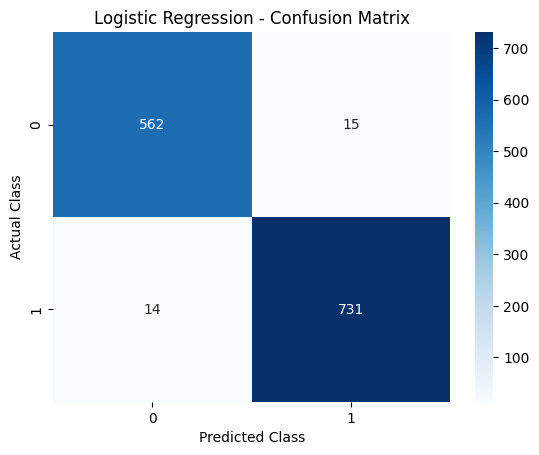

In [ ]:

cm = confusion_matrix(y_test_c, y_pred_c)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()


Accuracy: 0.8267776096822995
Precision: 0.8368146214099217
Recall: 0.8604026845637583
F1-Score: 0.8484447385837194


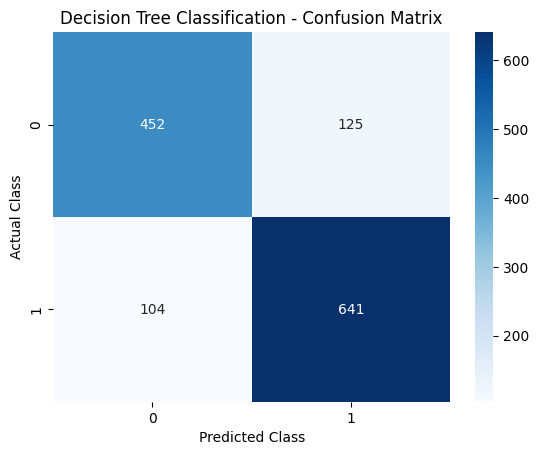

In [ ]:

from sklearn.tree import DecisionTreeClassifier

# Create and train the model
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train_c, y_train_c)

# Make predictions
dt_pred = dt_model.predict(X_test_c)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test_c, dt_pred))
print("Precision:", precision_score(y_test_c, dt_pred, zero_division=0))
print("Recall:", recall_score(y_test_c, dt_pred, zero_division=0))
print("F1-Score:", f1_score(y_test_c, dt_pred, zero_division=0))

# Display confusion matrix
cm = confusion_matrix(y_test_c, dt_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Decision Tree Classification - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()


Accuracy: 0.7677760968229954
Precision: 0.7800511508951407
Recall: 0.8187919463087249
F1-Score: 0.7989521938441388


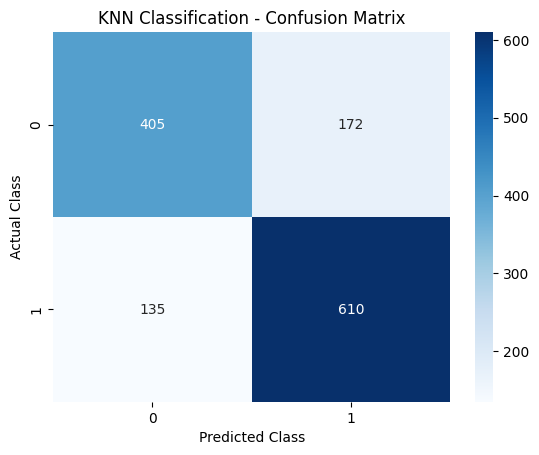

In [ ]:

from sklearn.neighbors import KNeighborsClassifier

# Create and train the KNN model
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train_c)

# Make predictions
knn_pred = knn_model.predict(X_test_scaled)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test_c, knn_pred))
print("Precision:", precision_score(y_test_c, knn_pred, zero_division=0))
print("Recall:", recall_score(y_test_c, knn_pred, zero_division=0))
print("F1-Score:", f1_score(y_test_c, knn_pred, zero_division=0))

# Display confusion matrix
cm = confusion_matrix(y_test_c, knn_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("KNN Classification - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()


Best K value: 14
Best Accuracy: 0.8290468986384266


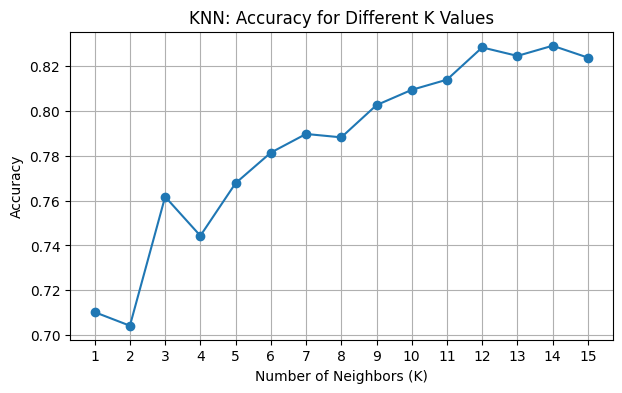

In [ ]:

k_values = range(1, 16)
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train_c)
    predictions = model.predict(X_test_scaled)
    accuracies.append(accuracy_score(y_test_c, predictions))

best_k = list(k_values)[accuracies.index(max(accuracies))]

print("Best K value:", best_k)
print("Best Accuracy:", max(accuracies))

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), accuracies, marker="o")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy")
plt.title("KNN: Accuracy for Different K Values")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()


Accuracy: 0.9508320726172466
Precision: 0.9545454545454546
Recall: 0.9583892617449664
F1-Score: 0.956463496316142


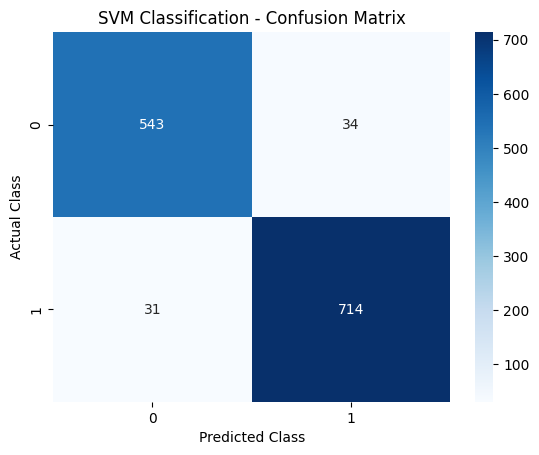

In [ ]:

from sklearn.svm import SVC

# Create and train the SVM model
svm_model = SVC(kernel="rbf", probability=True, random_state=42)
svm_model.fit(X_train_scaled, y_train_c)

# Make predictions
svm_pred = svm_model.predict(X_test_scaled)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test_c, svm_pred))
print("Precision:", precision_score(y_test_c, svm_pred, zero_division=0))
print("Recall:", recall_score(y_test_c, svm_pred, zero_division=0))
print("F1-Score:", f1_score(y_test_c, svm_pred, zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_test_c, svm_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("SVM Classification - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()


In [ ]:

svm_prob = svm_model.predict_proba(X_test_scaled)[:, 1]

print("AUC-ROC:", roc_auc_score(y_test_c, svm_prob))


AUC-ROC: 0.9893152501366709


In [ ]:

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Select features for clustering
cluster_columns = [
    col for col in ["Hours_Studied", "Attendance", "Previous_Scores"]
    if col in df.columns
]

if len(cluster_columns) < 2:
    raise ValueError("The dataset must contain at least two selected clustering features.")

cluster_data = df[cluster_columns].copy()

# Scale the data
cluster_scaler = StandardScaler()
cluster_scaled = cluster_scaler.fit_transform(cluster_data)

# Apply K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(cluster_scaled)

print("Cluster assignments:")
print(df["Cluster"].value_counts().sort_index())

print("\nAverage feature values in each cluster:")
display(df.groupby("Cluster")[cluster_columns].mean().round(2))


Cluster assignments:
Cluster
0    2122
1    2461
2    2024
Name: count, dtype: int64

Average feature values in each cluster:


,Hours_Studied,Attendance,Previous_Scores
Cluster,,,
0,20.16,69.28,66.77
1,20.38,80.36,90.28
2,19.28,90.73,65.29


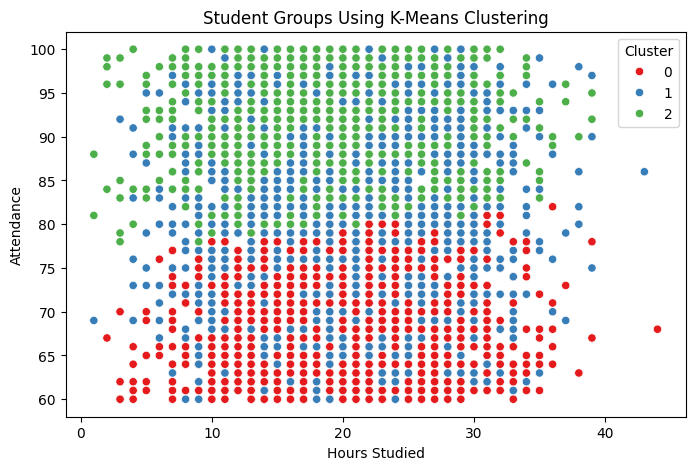

In [ ]:

if "Hours_Studied" in df.columns and "Attendance" in df.columns:
    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=df,
        x="Hours_Studied",
        y="Attendance",
        hue="Cluster",
        palette="Set1"
    )

    plt.title("Student Groups Using K-Means Clustering")
    plt.xlabel("Hours Studied")
    plt.ylabel("Attendance")
    plt.show()


In [ ]:

from sklearn.metrics import silhouette_score

score = silhouette_score(cluster_scaled, df["Cluster"])

print("Silhouette Score:", round(score, 4))


Silhouette Score: 0.2446


In [ ]:

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Apply hierarchical clustering
hierarchical = AgglomerativeClustering(n_clusters=3)

hierarchical_labels = hierarchical.fit_predict(cluster_scaled)

# Store cluster labels
df["Hierarchical_Cluster"] = hierarchical_labels

print("Number of students in each cluster:")
print(df["Hierarchical_Cluster"].value_counts().sort_index())

# Evaluate clustering
score = silhouette_score(cluster_scaled, hierarchical_labels)

print("Silhouette Score:", round(score, 4))


Number of students in each cluster:
Hierarchical_Cluster
0    2994
1    2285
2    1328
Name: count, dtype: int64
Silhouette Score: 0.1915


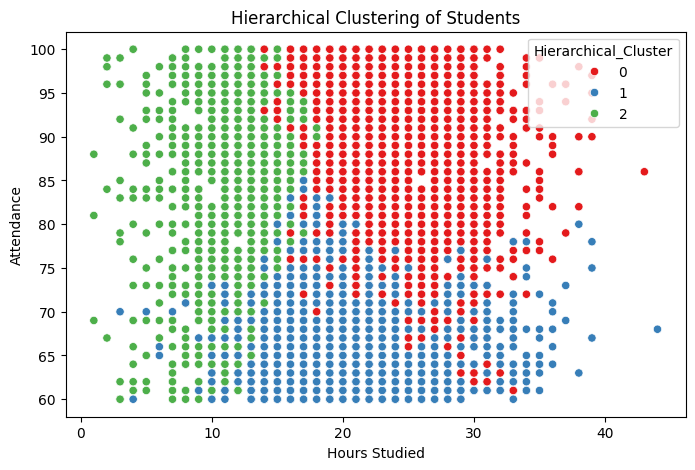

In [ ]:

if "Hours_Studied" in df.columns and "Attendance" in df.columns:
    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=df,
        x="Hours_Studied",
        y="Attendance",
        hue="Hierarchical_Cluster",
        palette="Set1"
    )

    plt.title("Hierarchical Clustering of Students")
    plt.xlabel("Hours Studied")
    plt.ylabel("Attendance")
    plt.show()


In [ ]:

from sklearn.datasets import fetch_openml
import numpy as np
import matplotlib.pyplot as plt

# Load MNIST handwritten digit dataset
X_mnist, y_mnist = fetch_openml(
    "mnist_784", version=1, return_X_y=True, as_frame=False
)

# Use a smaller subset to keep execution simple
X_mnist = X_mnist[:10000].astype("float32") / 255.0
y_mnist = y_mnist[:10000].astype("int64")

print("Image data shape:", X_mnist.shape)
print("Label data shape:", y_mnist.shape)


Image data shape: (10000, 784)
Label data shape: (10000,)


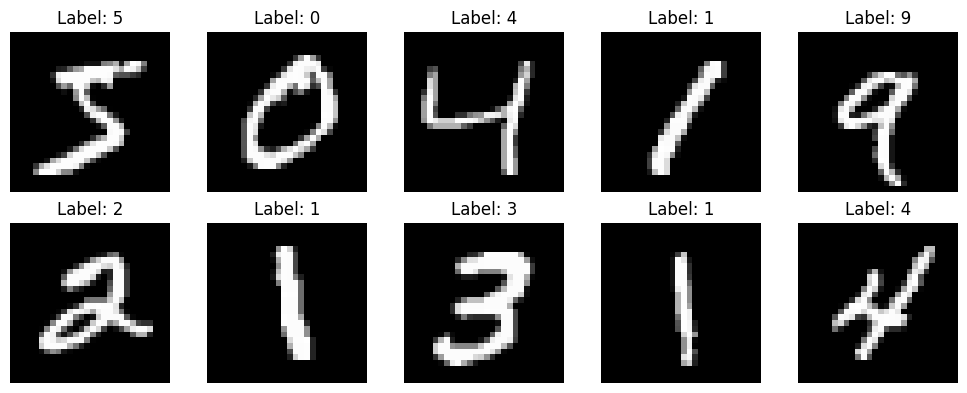

In [ ]:

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_mnist[i].reshape(28, 28), cmap="gray")
    plt.title(f"Label: {y_mnist[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

from sklearn.model_selection import train_test_split

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_mnist, y_mnist,
    test_size=0.2,
    random_state=42,
    stratify=y_mnist
)

print("Training images:", X_train_m.shape)
print("Testing images:", X_test_m.shape)


Training images: (8000, 784)
Testing images: (2000, 784)


In [ ]:

from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, classification_report

# Create and train the Perceptron
perceptron_model = Perceptron(max_iter=100, random_state=42)
perceptron_model.fit(X_train_m, y_train_m)

# Predict digit labels
perceptron_pred = perceptron_model.predict(X_test_m)

# Evaluate the model
print("Perceptron Accuracy:",
      accuracy_score(y_test_m, perceptron_pred))

print("\nClassification Report:")
print(classification_report(y_test_m, perceptron_pred))


Perceptron Accuracy: 0.8795

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.96      0.96       200
           1       0.89      0.98      0.93       225
           2       0.90      0.79      0.84       198
           3       0.89      0.75      0.81       206
           4       0.91      0.89      0.90       196
           5       0.84      0.83      0.83       173
           6       0.94      0.96      0.95       203
           7       0.91      0.87      0.89       214
           8       0.73      0.89      0.80       189
           9       0.85      0.85      0.85       196

    accuracy                           0.88      2000
   macro avg       0.88      0.88      0.88      2000
weighted avg       0.88      0.88      0.88      2000



In [ ]:

from sklearn.neural_network import MLPClassifier

# Create the MLP model
mlp_model = MLPClassifier(
    hidden_layer_sizes=(100,),
    max_iter=30,
    random_state=42
)

# Train the model
mlp_model.fit(X_train_m, y_train_m)

# Predict digit labels
mlp_pred = mlp_model.predict(X_test_m)

# Evaluate the model
print("MLP Accuracy:",
      accuracy_score(y_test_m, mlp_pred))

print("\nClassification Report:")
print(classification_report(y_test_m, mlp_pred))


MLP Accuracy: 0.943

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       200
           1       0.95      0.99      0.97       225
           2       0.91      0.91      0.91       198
           3       0.94      0.90      0.92       206
           4       0.95      0.93      0.94       196
           5       0.95      0.92      0.94       173
           6       0.95      0.97      0.96       203
           7       0.94      0.95      0.95       214
           8       0.92      0.94      0.93       189
           9       0.94      0.92      0.93       196

    accuracy                           0.94      2000
   macro avg       0.94      0.94      0.94      2000
weighted avg       0.94      0.94      0.94      2000



/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:

print("Perceptron Accuracy:",
      round(accuracy_score(y_test_m, perceptron_pred), 4))

print("MLP Accuracy:",
      round(accuracy_score(y_test_m, mlp_pred), 4))


Perceptron Accuracy: 0.8795
MLP Accuracy: 0.943


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


ANN Accuracy: 0.95

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       200
           1       0.97      0.99      0.98       225
           2       0.94      0.91      0.93       198
           3       0.92      0.93      0.92       206
           4       0.95      0.94      0.95       196
           5       0.96      0.93      0.94       173
           6       0.95      0.98      0.97       203
           7       0.94      0.97      0.95       214
           8       0.94      0.94      0.94       189
           9       0.95      0.92      0.94       196

    accuracy                           0.95      2000
   macro avg       0.95      0.95      0.95      2000
weighted avg       0.95      0.95      0.95      2000



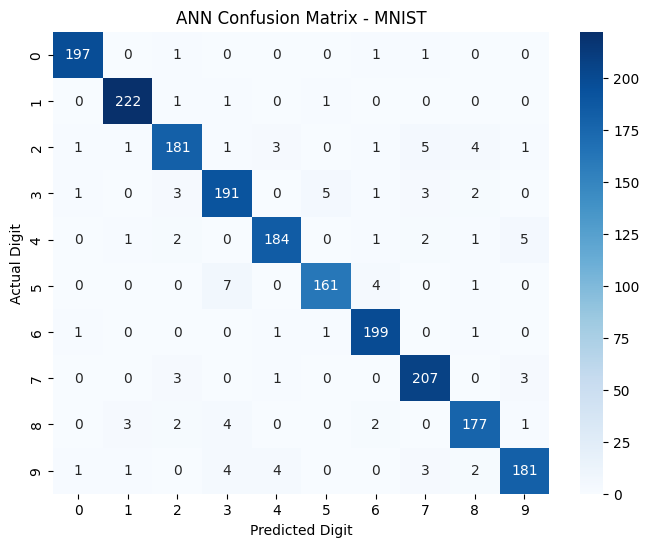

In [ ]:

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Create ANN model
ann_model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    max_iter=30,
    random_state=42
)

# Train the model
ann_model.fit(X_train_m, y_train_m)

# Predict digits
ann_pred = ann_model.predict(X_test_m)

# Evaluate
print("ANN Accuracy:", accuracy_score(y_test_m, ann_pred))
print("\nClassification Report:")
print(classification_report(y_test_m, ann_pred))

# Confusion matrix
cm = confusion_matrix(y_test_m, ann_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("ANN Confusion Matrix - MNIST")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.show()


In [ ]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# KNN
knn_mnist = KNeighborsClassifier(n_neighbors=5)
knn_mnist.fit(X_train_m, y_train_m)
knn_mnist_pred = knn_mnist.predict(X_test_m)

# SVM
svm_mnist = SVC(kernel="rbf")
svm_mnist.fit(X_train_m, y_train_m)
svm_mnist_pred = svm_mnist.predict(X_test_m)

# Compare accuracy
results = pd.DataFrame({
    "Model": ["ANN", "KNN", "SVM"],
    "Accuracy": [
        accuracy_score(y_test_m, ann_pred),
        accuracy_score(y_test_m, knn_mnist_pred),
        accuracy_score(y_test_m, svm_mnist_pred)
    ]
})

display(results)


,Model,Accuracy
0,ANN,0.9500
1,KNN,0.9375
2,SVM,0.9530


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

mnist_results = pd.DataFrame({
    "Model": ["ANN", "KNN", "SVM"],
    "Accuracy": [
        accuracy_score(y_test_m, ann_pred),
        accuracy_score(y_test_m, knn_mnist_pred),
        accuracy_score(y_test_m, svm_mnist_pred)
    ],
    "Precision": [
        precision_score(y_test_m, ann_pred, average="weighted"),
        precision_score(y_test_m, knn_mnist_pred, average="weighted"),
        precision_score(y_test_m, svm_mnist_pred, average="weighted")
    ],
    "Recall": [
        recall_score(y_test_m, ann_pred, average="weighted"),
        recall_score(y_test_m, knn_mnist_pred, average="weighted"),
        recall_score(y_test_m, svm_mnist_pred, average="weighted")
    ],
    "F1-Score": [
        f1_score(y_test_m, ann_pred, average="weighted"),
        f1_score(y_test_m, knn_mnist_pred, average="weighted"),
        f1_score(y_test_m, svm_mnist_pred, average="weighted")
    ]
})

display(mnist_results.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,ANN,0.9500,0.9500,0.9500,0.9499
1,KNN,0.9375,0.9393,0.9375,0.9372
2,SVM,0.9530,0.9529,0.9530,0.9528


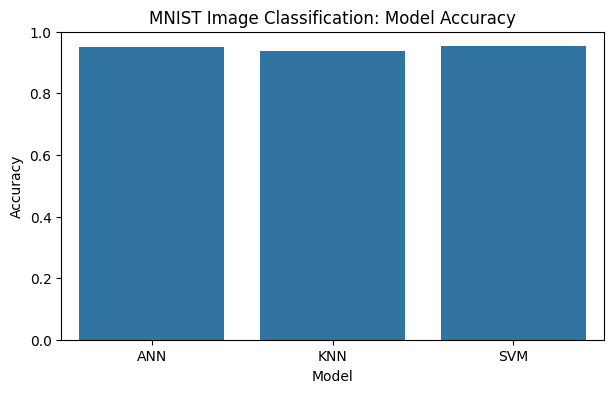

In [ ]:

plt.figure(figsize=(7, 4))
sns.barplot(data=results, x="Model", y="Accuracy")
plt.title("MNIST Image Classification: Model Accuracy")
plt.ylim(0, 1)
plt.show()


In [ ]:

# Check the regression target
print("Exam_Score in regression inputs:", "Exam_Score" in X.columns)

# Check the classification inputs
print("Exam_Score in classification inputs:", "Exam_Score" in X_train_c.columns)

# Check the classification target
print("\nClassification target distribution:")
print(y_class.value_counts())

# Check for missing values
print("\nMissing values in regression inputs:", X.isnull().sum().sum())
print("Missing values in classification inputs:", X_train_c.isnull().sum().sum())


Exam_Score in regression inputs: False
Exam_Score in classification inputs: False

Classification target distribution:
Exam_Score
1    3725
0    2882
Name: count, dtype: int64

Missing values in regression inputs: 0
Missing values in classification inputs: 0


In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor
import numpy as np
import pandas as pd

# Create and train Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Evaluate Linear Regression
linear_pred = linear_model.predict(X_test)

# Evaluate Decision Tree Regression
tree_pred = tree_reg.predict(X_test)

# Create results table
regression_results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree Regression"],
    "MAE": [
        mean_absolute_error(y_test, linear_pred),
        mean_absolute_error(y_test, tree_pred)
    ],
    "MSE": [
        mean_squared_error(y_test, linear_pred),
        mean_squared_error(y_test, tree_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, linear_pred)),
        np.sqrt(mean_squared_error(y_test, tree_pred))
    ],
    "R2 Score": [
        r2_score(y_test, linear_pred),
        r2_score(y_test, tree_pred)
    ]
})

display(regression_results.round(4))



,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.4524,3.256,1.8044,0.7696
1,Decision Tree Regression,1.5998,6.308,2.5116,0.5537


In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Train a fresh Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predict exam scores
linear_pred = linear_model.predict(X_test)

# Evaluate the model
print("Linear Regression Results")
print("-------------------------")
print("MAE:", round(mean_absolute_error(y_test, linear_pred), 4))
print("MSE:", round(mean_squared_error(y_test, linear_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, linear_pred)), 4))
print("R2 Score:", round(r2_score(y_test, linear_pred), 4))


Linear Regression Results
-------------------------
MAE: 0.4524
MSE: 3.256
RMSE: 1.8044
R2 Score: 0.7696
